# Data Wrangling
---

## Objectives
After completing this you will be able to:

- Handle missing values
- Correct data formating
- Standardise and normalize Data
  
## Table of Contents
- Identify and handle missing values
  - Identify missing values
  - Deal with missing values
  - Correct data format
- Data standardization
- Data normalization (centering/scaling)
- Binning
- Indicator variable



## What is the purpose of data wrangling?

You use data wrangling to convert data from an initial format to a format that may be better for analysis.

---

## What is the fuel consumption (L/100k) rate for the diesel car?

---

## Import Data

You can find the Automobile Dataset from the following link:
https://archive.ics.uci.edu/ml/machine-learning-databases/autos/imports-85.data

You will be using this data set throughout this course.

### Import pandas

In [46]:
import pandas as pd
import matplotlib as plt

## 2- Reading the file from url and adding headers

In [47]:

filename = "https://archive.ics.uci.edu/ml/machine-learning-databases/autos/imports-85.data"
df=pd.read_csv (filename,)
df.head()
headers=["symboling","normalized-losses","make","fuel-type","aspiration",
           "num-of-doors","body-style","drive-wheels","engine-location",
           "wheel-base","length","width","height","curb-weight","engine-type",
           "num-of-cylinders","engine-size","fuel-system","bore","stroke",
           "compression-ratio","horsepower","peak-rpm","city-mpg",
           "highway-mpg","price"]
df.columns=headers
df.head()



,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,3,?,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500
1,1,?,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500
2,2,164,audi,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950
3,2,164,audi,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450
4,2,?,audi,gas,std,two,sedan,fwd,front,99.8,...,136,mpfi,3.19,3.40,8.5,110,5500,19,25,15250


## 3- Identify and handle missing values
### convert ? to NaN by "replace" function

In [48]:
import numpy as np
df.replace("?", np.nan, inplace= True)  
df.dtypes

symboling              int64
normalized-losses     object
make                  object
fuel-type             object
aspiration            object
num-of-doors          object
body-style            object
drive-wheels          object
engine-location       object
wheel-base           float64
length               float64
width                float64
height               float64
curb-weight            int64
engine-type           object
num-of-cylinders      object
engine-size            int64
fuel-system           object
bore                  object
stroke                object
compression-ratio    float64
horsepower            object
peak-rpm              object
city-mpg               int64
highway-mpg            int64
price                 object
dtype: object

## 4- Evaluating for Missing Data

The missing values are converted by default. Use the following functions to identify missing values:

1. `.isnull()`
2. `.notnull()`

The output is a **boolean** value:
- `True` = value IS missing
- `False` = value is NOT missing

In [49]:
missing_data=df.isnull()
missing_data.head()

,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,False,True,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,False,True,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,False,True,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


## 5-Count missing values in each column

Using a for loop to count the number of missing values (`True`) in each column:

In [50]:
for column in missing_data.columns:
  print(column)
  print(missing_data[column].value_counts())
  print()
  #OR
  #for column in missing_data.columns:
    #print(missing_data[column].value_counts())
    #print()

symboling
symboling
False    204
Name: count, dtype: int64

normalized-losses
normalized-losses
False    164
True      40
Name: count, dtype: int64

make
make
False    204
Name: count, dtype: int64

fuel-type
fuel-type
False    204
Name: count, dtype: int64

aspiration
aspiration
False    204
Name: count, dtype: int64

num-of-doors
num-of-doors
False    202
True       2
Name: count, dtype: int64

body-style
body-style
False    204
Name: count, dtype: int64

drive-wheels
drive-wheels
False    204
Name: count, dtype: int64

engine-location
engine-location
False    204
Name: count, dtype: int64

wheel-base
wheel-base
False    204
Name: count, dtype: int64

length
length
False    204
Name: count, dtype: int64

width
width
False    204
Name: count, dtype: int64

height
height
False    204
Name: count, dtype: int64

curb-weight
curb-weight
False    204
Name: count, dtype: int64

engine-type
engine-type
False    204
Name: count, dtype: int64

num-of-cylinders
num-of-cylinders
False    204
Nam

## How should you deal with missing data?

1. Drop data
   - a. Drop the whole row
   - b. Drop the whole column
2. Replace data
   - a. Replace by mean
   - b. Replace by frequency
   - c. Replace based on other functions

> Only drop whole columns if **most** entries are empty.

### Replace by mean:
- `normalized-losses`: 41 missing → replace with mean
- `stroke`: 4 missing → replace with mean
- `bore`: 4 missing → replace with mean
- `horsepower`: 2 missing → replace with mean
- `peak-rpm`: 2 missing → replace with mean

### Replace by frequency:
- `num-of-doors`: 2 missing → replace with "four"
  - Reason: 84% sedans have four doors — most frequent value

### Drop the whole row:
- `price`: 4 missing → drop the entire row
- Reason: We want to **predict price** — any row 
  without a price is useless for our analysis

In [51]:
#### Calculate the mean value for the "normalized-losses" column
avg_norm_loss=df["normalized-losses"].astype("float").mean(0)
print("average nomalise loss is:",avg_norm_loss)
#now lets replace each NaN value with 122 of with the replace function again as we did before.
df["normalized-losses"].replace(np.nan, avg_norm_loss, inplace=True)
df.head()


#Memory trick
#PICK → CONVERT → CALCULATE → SAVE → SHOW → FILL
 #df[]  .astype()   .mean()     =     print  .replace()



average nomalise loss is: 122.0


C:\Users\shair\AppData\Local\Temp\ipykernel_25844\3077032525.py:5: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df["normalized-losses"].replace(np.nan, avg_norm_loss, inplace=True)


,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,3,122.0,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500
1,1,122.0,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500
2,2,164,audi,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950
3,2,164,audi,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450
4,2,122.0,audi,gas,std,two,sedan,fwd,front,99.8,...,136,mpfi,3.19,3.40,8.5,110,5500,19,25,15250


In [52]:
# bore
avg_bore=df["bore"].astype("float").mean(axis=0)

df["bore"].replace(np.nan, avg_bore, inplace=True)

C:\Users\shair\AppData\Local\Temp\ipykernel_25844\3340879337.py:4: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df["bore"].replace(np.nan, avg_bore, inplace=True)


## REPLACE BY FREQUENCY — categorical columns another waytor replace missing values

In [53]:

# num-of-doors — most frequent value is "four"
df["num-of-doors"].replace(np.nan, "four", inplace=True)

C:\Users\shair\AppData\Local\Temp\ipykernel_25844\547708414.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df["num-of-doors"].replace(np.nan, "four", inplace=True)


## DROP WHOLE ROW — price column

In [54]:
# price is what we predict — useless without it
df.dropna(subset=["price"], axis=0, inplace=True)
# reset index after dropping rows
df.reset_index(drop=True, inplace=True)

# ============================================
# VERIFY — check no missing values remain
# ============================================

In [55]:
print(df.isnull().sum())
df.head()

symboling            0
normalized-losses    0
make                 0
fuel-type            0
aspiration           0
num-of-doors         0
body-style           0
drive-wheels         0
engine-location      0
wheel-base           0
length               0
width                0
height               0
curb-weight          0
engine-type          0
num-of-cylinders     0
engine-size          0
fuel-system          0
bore                 0
stroke               4
compression-ratio    0
horsepower           2
peak-rpm             2
city-mpg             0
highway-mpg          0
price                0
dtype: int64


,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,3,122.0,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500
1,1,122.0,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500
2,2,164,audi,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950
3,2,164,audi,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450
4,2,122.0,audi,gas,std,two,sedan,fwd,front,99.8,...,136,mpfi,3.19,3.40,8.5,110,5500,19,25,15250


# Or full code from start to end 

In [56]:
import pandas as pd
import numpy as np

# ============================================
# LOAD DATA
# ============================================
filename = "https://archive.ics.uci.edu/ml/machine-learning-databases/autos/imports-85.data"
df = pd.read_csv(filename, header=None)

# ============================================
# ADD HEADERS
# ============================================
headers = ["symboling","normalized-losses","make","fuel-type","aspiration",
           "num-of-doors","body-style","drive-wheels","engine-location",
           "wheel-base","length","width","height","curb-weight","engine-type",
           "num-of-cylinders","engine-size","fuel-system","bore","stroke",
           "compression-ratio","horsepower","peak-rpm","city-mpg",
           "highway-mpg","price"]
df.columns = headers
df.head()

# ============================================
# IDENTIFY MISSING VALUES
# ============================================
missing_data = df.isnull()
missing_data.head(5)

# COUNT missing values in each column
for column in missing_data.columns:
    print(missing_data[column].value_counts())
    print()

# ============================================
# REPLACE BY MEAN — numerical columns
# ============================================

# STEP 1 — Replace ALL '?' with NaN first!
df = df.replace('?', np.nan)

# STEP 2 — NOW you can calculate mean and replace
avg_norm_loss = df["normalized-losses"].astype("float").mean(axis=0)
print("Average of normalized-losses:", avg_norm_loss)
df["normalized-losses"]=df["normalized-losses"].replace(np.nan, avg_norm_loss)
# bore
avg_bore = df["bore"].astype("float").mean(axis=0)
print("Average of bore:", avg_bore)
df["bore"]=df["bore"].replace(np.nan, avg_bore)

# stroke
avg_stroke = df["stroke"].astype("float").mean(axis=0)
print("Average of stroke:", avg_stroke)
df["stroke"]=df["stroke"].replace(np.nan, avg_stroke)

# horsepower
avg_horsepower = df["horsepower"].astype("float").mean(axis=0)
print("Average of horsepower:", avg_horsepower)
df["horsepower"]=df["horsepower"].replace(np.nan, avg_horsepower)

# peak-rpm
avg_peakrpm = df["peak-rpm"].astype("float").mean(axis=0)
print("Average of peak-rpm:", avg_peakrpm)
df["peak-rpm"]=df["peak-rpm"].replace(np.nan, avg_peakrpm,)

# ============================================
# REPLACE BY FREQUENCY — categorical columns
# ============================================

# num-of-doors — most frequent value is "four"
df["num-of-doors"]=df["num-of-doors"].replace(np.nan, "four")

# ============================================
# DROP WHOLE ROW — price column
# ============================================

# price is what we predict — useless without it
df.dropna(subset=["price"], axis=0, inplace=True)

# reset index after dropping rows
df.reset_index(drop=True, inplace=True)

# ============================================
# VERIFY — check no missing values remain
# ============================================
print(df.isnull().sum())

df.head()

symboling
False    205
Name: count, dtype: int64

normalized-losses
False    205
Name: count, dtype: int64

make
False    205
Name: count, dtype: int64

fuel-type
False    205
Name: count, dtype: int64

aspiration
False    205
Name: count, dtype: int64

num-of-doors
False    205
Name: count, dtype: int64

body-style
False    205
Name: count, dtype: int64

drive-wheels
False    205
Name: count, dtype: int64

engine-location
False    205
Name: count, dtype: int64

wheel-base
False    205
Name: count, dtype: int64

length
False    205
Name: count, dtype: int64

width
False    205
Name: count, dtype: int64

height
False    205
Name: count, dtype: int64

curb-weight
False    205
Name: count, dtype: int64

engine-type
False    205
Name: count, dtype: int64

num-of-cylinders
False    205
Name: count, dtype: int64

engine-size
False    205
Name: count, dtype: int64

fuel-system
False    205
Name: count, dtype: int64

bore
False    205
Name: count, dtype: int64

stroke
False    205
Name: count,

,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,3,122.0,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495
1,3,122.0,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500
2,1,122.0,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500
3,2,164,audi,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950
4,2,164,audi,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450


In [57]:
df.dtypes


symboling              int64
normalized-losses     object
make                  object
fuel-type             object
aspiration            object
num-of-doors          object
body-style            object
drive-wheels          object
engine-location       object
wheel-base           float64
length               float64
width                float64
height               float64
curb-weight            int64
engine-type           object
num-of-cylinders      object
engine-size            int64
fuel-system           object
bore                  object
stroke                object
compression-ratio    float64
horsepower            object
peak-rpm              object
city-mpg               int64
highway-mpg            int64
price                 object
dtype: object

In [58]:
# Convert all numeric columns to correct dtype
df["normalized-losses"] = df["normalized-losses"].astype("float")
df["bore"] = df["bore"].astype("float")
df["stroke"] = df["stroke"].astype("float")
df["horsepower"] = df["horsepower"].astype("float")
df["peak-rpm"] = df["peak-rpm"].astype("float")
df["price"] = df["price"].astype("float")

# Verify
print(df.dtypes)

symboling              int64
normalized-losses    float64
make                  object
fuel-type             object
aspiration            object
num-of-doors          object
body-style            object
drive-wheels          object
engine-location       object
wheel-base           float64
length               float64
width                float64
height               float64
curb-weight            int64
engine-type           object
num-of-cylinders      object
engine-size            int64
fuel-system           object
bore                 float64
stroke               float64
compression-ratio    float64
horsepower           float64
peak-rpm             float64
city-mpg               int64
highway-mpg            int64
price                float64
dtype: object


## Data Standardization

You usually collect data from different agencies in different formats.

**What is standardization?**

Standardization is the process of transforming data into a common format, 
allowing meaningful comparison between variables.

**Example — Transform mpg to L/100km:**

- `city-mpg` and `highway-mpg` are in **miles per gallon (mpg)**
- We need to convert to **L/100km** (metric standard)

**Formula:**
```
L/100km = 235 / mpg
```

In [59]:
df.head()

,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,3,122.0,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,13495.0
1,3,122.0,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,16500.0
2,1,122.0,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154.0,5000.0,19,26,16500.0
3,2,164.0,audi,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102.0,5500.0,24,30,13950.0
4,2,164.0,audi,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115.0,5500.0,18,22,17450.0


In [60]:
# Convert city-mpg to L/100km
df["city-L/100km"]= 235/df["city-mpg"]
df["highway-L/100km"]= 235/df["highway-mpg"]
df.drop(columns=["city-mpg", "highway-mpg"], inplace=True)

df.head()

,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,price,city-L/100km,highway-L/100km
0,3,122.0,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111.0,5000.0,13495.0,11.190476,8.703704
1,3,122.0,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111.0,5000.0,16500.0,11.190476,8.703704
2,1,122.0,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154.0,5000.0,16500.0,12.368421,9.038462
3,2,164.0,audi,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102.0,5500.0,13950.0,9.791667,7.833333
4,2,164.0,audi,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115.0,5500.0,17450.0,13.055556,10.681818


#### Or if you want to create new column and then drop the old previous code is okay but if you want to convert the column and then rename the same column with rename() function. it will not create duplicate 
df.rename(columns={"highway-mpg": "highway-L/100km"}, inplace=True)

## Data Normalization

**Why normalization?**

Normalization transforms values of several variables into a similar range.

Typical normalizations include:
1. Scaling so the variable average is 0
2. Scaling so the variance is 1
3. Scaling so the values range from **0 to 1**

**Example — normalize length, width and height**

- **Target:** values range from 0 to 1
- **Approach:** divide each value by the maximum value of that column

> Formula: new value = original value / maximum value

In [61]:
# Simple feature scaling — divide by max value
df["length"] = df["length"] / df["length"].max()
df["width"] = df["width"] / df["width"].max()

df[["length", "width"]].head()

,length,width
0,0.811148,0.890278
1,0.811148,0.890278
2,0.822681,0.909722
3,0.848630,0.919444
4,0.848630,0.922222


### Question 3
Normalize the column **"height"** using the same approach.

In [62]:
df["height"]=df["height"]/df["height"].max()
# Verify — should now be between 0 and 1
df[["length", "width", "height"]].head()

,length,width,height
0,0.811148,0.890278,0.816054
1,0.811148,0.890278,0.816054
2,0.822681,0.909722,0.876254
3,0.848630,0.919444,0.908027
4,0.848630,0.922222,0.908027


## Normalization Methods — Complete Reference

---

### What is Normalization?
> Bring all features to the **same scale** so no single feature 
> dominates just because of its larger size.

---

### All Normalization Methods Compared

| Method | Formula | Result Range | Best For |
|---|---|---|---|
| **Simple Scaling** | value / max | 0 to 1 | Quick, easy normalization |
| **Min-Max** | (value - min) / (max - min) | 0 to 1 | Precise 0-1 range needed |
| **Z-Score** | (value - mean) / std | -3 to +3 | Bell shaped / normal data |
| **Quantile** | Ranks data uniformly | 0 to 1 | Skewed data with outliers |
| **Box-Cox** | Log-based transformation | Varies | Making skewed data normal |

---

### Code for Each Method

**1. Simple Feature Scaling**
```python
df["length"] = df["length"] / df["length"].max()
```

**2. Min-Max**
```python
df["length"] = (df["length"] - df["length"].min()) / \
               (df["length"].max() - df["length"].min())
```

**3. Z-Score**
```python
df["length"] = (df["length"] - df["length"].mean()) / \
                df["length"].std()
```

**4. Quantile**
```python
from sklearn.preprocessing import QuantileTransformer
qt = QuantileTransformer()
df["length"] = qt.fit_transform(df[["length"]])
```

**5. Box-Cox**
```python
from scipy.stats import boxcox
df["length"], _ = boxcox(df["length"])
```

---

### When to Use Which?

| Situation | Use |
|---|---|
| Just starting out | Simple Scaling |
| Need exact 0 to 1 range | Min-Max |
| Data is bell shaped | Z-Score |
| Data has outliers / heavily skewed | Quantile |
| Data is non-normal and positive | Box-Cox |

---

### One Line Memory Trick
> *"Normalization doesn't change the data's meaning — 
> it just changes the size of the numbers 
> so everyone plays fairly"* 🎯

---

### Real Life Analogy
Like converting currencies to one standard:
- USA → Dollars
- Italy → Euros
- Pakistan → Rupees

You convert to a **common standard** to compare fairly.
Normalization does the same for your data! 🍼

## Binning

**Why binning?**
Binning transforms continuous numerical variables into 
discrete categorical bins for grouped analysis.

**Example:**
- `horsepower` ranges from 48 to 288 with 59 unique values
- We simplify into 3 bins: **Low, Medium, High**

**Why convert to int first?**
- Mean replacement created decimals e.g. `104.256`
- Horsepower should be whole numbers e.g. `104`
- Binning works cleaner with integers

**Steps:**
1. Convert to correct data type → `astype(int)`
2. Plot histogram to see distribution
3. Create bins with `np.linspace()`
4. Cut data into bins with `pd.cut()`
5. Visualise with bar chart

# Memory trick
BEFORE binning always ask:
1. Is the data type correct?  → astype(int)
2. What does distribution look like? → histogram
3. Then bin it! → np.linspace + pd.cut

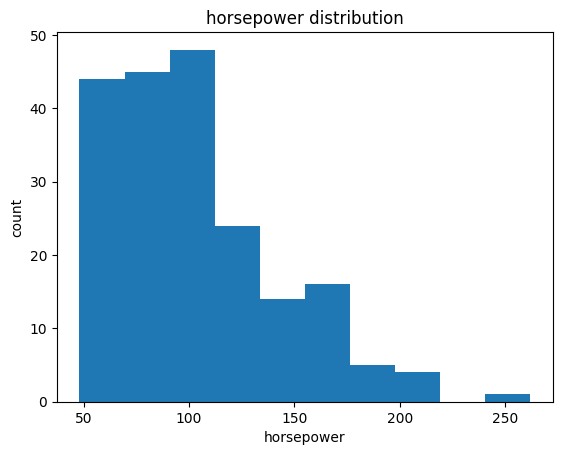

In [63]:
df["horsepower"].dtypes
df["horsepower"]= df["horsepower"].astype(int, copy=True)
df["horsepower"].dtypes
# STEP 2 — Plot histogram to see distribution BEFORE binning
# %matplotlib inline = show plot inside notebook
%matplotlib inline
import matplotlib.pyplot as plt
plt.hist(df["horsepower"])

plt.xlabel("horsepower")
plt.ylabel("count")
plt.title("horsepower distribution")
# Save to images folder BEFORE show()
plt.savefig("../images/horsepower_histogram.png",
            dpi=150,
            bbox_inches="tight")
plt.show()
#As we can see how many cars have horse power most of the cars have horse power more than hundred less cars have 250 horse power

In [64]:
df["horsepower"].nunique()


59

## Binning — Horsepower Example

**Goal:** Reduce 59 unique horsepower values → just 3 categories
4 dividers = 3 bins (always need one extra divider!)
[48 ---- 119 ---- 190 ---- 288]
Low     Medium    High

**Result:** narrowed down from **59 unique values → just 3 bins!**

In [65]:
# Convert to int and SAVE it
df["horsepower"] = df["horsepower"].astype(float).astype(int)

# STEP 1 — Create 4 equally spaced dividers
# min=start, max=end, 4=number of dividers (3 bins need 4 dividers!)
bins= np.linspace(min(df["horsepower"]), max(df["horsepower"]),4)
print("bin deviders:", bins)

# STEP 2 — Name the 3 bins
group_names = ["Low", "Medium", "High"]

# STEP 3 — Cut into bins
df["horsepower-binned"] = pd.cut(df["horsepower"], bins, labels=group_names, include_lowest=True)
# STEP 4 — Check result- we have also created new column with horsepower-binned 
df[["horsepower", "horsepower-binned"]].head(20)


bin deviders: [ 48.         119.33333333 190.66666667 262.        ]


,horsepower,horsepower-binned
0,111,Low
1,111,Low
2,154,Medium
3,102,Low
4,115,Low
5,110,Low
6,110,Low
7,110,Low
8,140,Medium
9,101,Low


In [66]:
# STEP 5 — Count cars in each bin
# How many Low, Medium, High cars are there?
df["horsepower-binned"].value_counts()
df.head()

,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,...,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,price,city-L/100km,highway-L/100km,horsepower-binned
0,3,122.0,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,mpfi,3.47,2.68,9.0,111,5000.0,13495.0,11.190476,8.703704,Low
1,3,122.0,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,mpfi,3.47,2.68,9.0,111,5000.0,16500.0,11.190476,8.703704,Low
2,1,122.0,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,...,mpfi,2.68,3.47,9.0,154,5000.0,16500.0,12.368421,9.038462,Medium
3,2,164.0,audi,gas,std,four,sedan,fwd,front,99.8,...,mpfi,3.19,3.40,10.0,102,5500.0,13950.0,9.791667,7.833333,Low
4,2,164.0,audi,gas,std,four,sedan,4wd,front,99.4,...,mpfi,3.19,3.40,8.0,115,5500.0,17450.0,13.055556,10.681818,Low


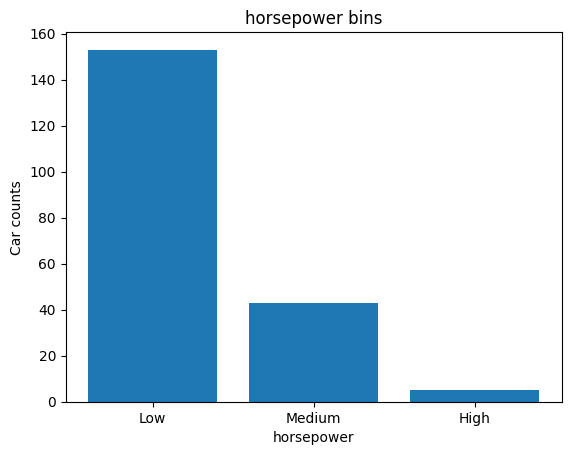

In [67]:
# STEP 6 — Bar chart — count per bin category
%matplotlib inline
import matplotlib.pyplot as plt
plt.bar(group_names, df["horsepower-binned"].value_counts())
plt.xlabel("horsepower")
plt.ylabel("Car counts")
plt.title("horsepower bins")
# Save to images folder BEFORE show()
plt.savefig("../images/horsepower_bar_chart.png", 
            dpi=150, 
            bbox_inches="tight")
plt.show()


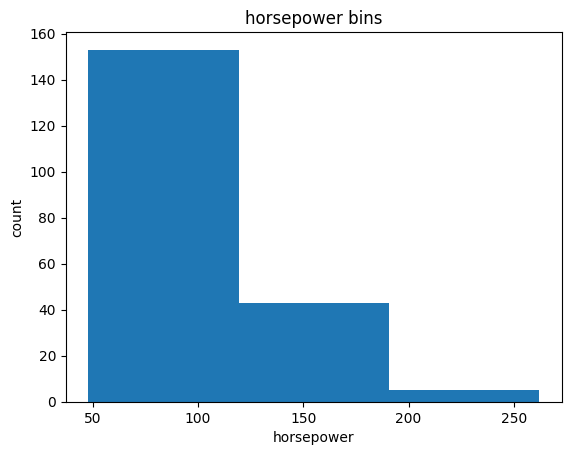

In [68]:
# STEP 7 — Histogram — distribution with 3 bins
# bins=3 matches our 3 categories (Low/Medium/High)
plt.hist(df["horsepower"], bins=3)
plt.xlabel("horsepower")
plt.ylabel("count")
plt.title("horsepower bins")
# Save to images folder BEFORE show()
plt.savefig("../images/horsepower_histogram_1.png",
            dpi=150,
            bbox_inches="tight")
plt.show()

## Memory Trick

BINNING = SORTING into BUCKETS

np.linspace → CREATE the bucket dividers
pd.cut      → SORT values into buckets
value_counts → COUNT items in each bucket

Always: dividers = bins + 1
        3 bins need 4 dividers
        4 bins need 5 dividers

Also

plt.bar()    ✅
plt.hist()   ✅
plt.xlabel() ✅
plt.show()   ✅

# ❌ Wrong
import matplotlib as plt

# ✅ Correct
import matplotlib.pyplot as plt

### Common Mistakes to Remember 🚨

---

### 1. Missing `.pyplot` in import
```python
# ❌ Wrong
import matplotlib as plt

# ✅ Correct
import matplotlib.pyplot as plt
```

---

### 2. Writing `plt.pyplot` instead of just `plt`
```python
# ❌ Wrong — pyplot twice!
plt.pyplot.hist(df["horsepower"])

# ✅ Correct
plt.hist(df["horsepower"])
```

---

### 3. Not saving the result of astype()
```python
# ❌ Wrong — result is lost!
df["horsepower"].astype(int)

# ✅ Correct — save it back!
df["horsepower"] = df["horsepower"].astype(int)
```

---

### 4. Passing variable name as string in read_csv
```python
# ❌ Wrong — looks for a FILE called "filename"
df = pd.read_csv("filename")

# ✅ Correct — pass the variable without quotes
df = pd.read_csv(filename)
```

---

### 5. Variable name with space
```python
# ❌ Wrong — spaces not allowed!
file name = "https://..."

# ✅ Correct
filename = "https://..."
```

---

### 6. Not replacing '?' with NaN before calculating mean
```python
# ❌ Wrong — '?' breaks astype("float")!
df["horsepower"].astype("float").mean()

# ✅ Correct — replace '?' first!
df = df.replace('?', np.nan)
df["horsepower"].astype("float").mean()
```

---

### 7. Using inplace=True with new pandas (FutureWarning)
```python
# ❌ Old way — causes FutureWarning in pandas 3.0
df["col"].replace(np.nan, value, inplace=True)

# ✅ New way
df["col"] = df["col"].replace(np.nan, value)
```

---

### 8. Wrong order — using df.head() before adding headers
```python
# ❌ Wrong order
df = pd.read_csv(filename)
df.head()        # ← too early!
df.columns = headers

# ✅ Correct order
df = pd.read_csv(filename)
df.columns = headers
df.head()        # ← now correct!
```

---

### 9. Single [] for multiple columns
```python
# ❌ Wrong — KeyError!
df["length", "width"]

# ✅ Correct — double [[]]
df[["length", "width"]]
```

---

### 10. Running cells out of order
```python
# ❌ Wrong — using np before importing!
df = df.replace('?', np.nan)  # NameError: np not defined

# ✅ Correct — always import first!
import numpy as np            # run this cell first!
df = df.replace('?', np.nan)  # then this works!
```

---

### 11. Forgetting dropna vs replace
```python
# dropna — REMOVES the row entirely
df.dropna(subset=["price"], axis=0, inplace=True)

# replace — FILLS the missing value
df["col"] = df["col"].replace(np.nan, mean_value)

# Rule:
# price column → dropna (can't predict without it)
# other columns → replace with mean/mode
```

---

### 12. linspace needs bins + 1 dividers
```python
# ❌ Wrong — 3 dividers only makes 2 bins!
bins = np.linspace(min, max, 3)

# ✅ Correct — 4 dividers makes 3 bins!
bins = np.linspace(min, max, 4)

# Rule: always bins + 1
# 3 bins → 4 dividers
# 4 bins → 5 dividers
```

---

### 13. Not running import cell before code cells
```
Always run cells TOP TO BOTTOM!
[ ] import cell     ← run this FIRST (Shift+Enter)
[ ] load data cell  ← then this
[ ] headers cell    ← then this
[ ] code cell       ← then this last
```

---

### Golden Rules ⭐
> 1. Always `import numpy as np` and `import pandas as pd` first
> 2. Always replace `'?'` with `np.nan` before any calculations
> 3. Always save results back → `df["col"] = df["col"].method()`
> 4. Always run cells top to bottom
> 5. `plt` = `pyplot` — never write both!

## Indicator Variable (Dummy Variable)

**What is it?**
A numerical variable (0 or 1) used to represent text categories
so regression models can understand them.

**Why use it?**
- Models only understand numbers — not words like "gas" or "diesel"
- `get_dummies()` converts text → 0s and 1s

**Example — fuel-type:**

| fuel-type | fuel-type-gas | fuel-type-diesel |
|---|---|---|
| gas | 1 | 0 |
| diesel | 0 | 1 |
| gas | 1 | 0 |

**Rule:** Only ONE column is 1 at a time → called One-Hot Encoding

**Steps:**
1. Check columns → `df.columns`
2. Create dummies → `pd.get_dummies()`
3. Rename columns → `.rename()`
4. Merge back → `pd.concat()`
5. Drop original → `df.drop()`

In [69]:
# STEP 1 — Check existing columns before adding dummies
df.columns

# STEP 2 — Create dummy variables from fuel-type
# dtype=int → gives 0s and 1s instead of True/False
dummy_variable_1 = pd.get_dummies(df["fuel-type"], dtype=int)

# STEP 3 — Rename columns so we know where they came from
dummy_variable_1 = dummy_variable_1.rename(columns={
    "gas"    : "fuel-type-gas",
    "diesel" : "fuel-type-diesel"
})

# STEP 4 — Merge dummy columns into original dataframe
# axis=1 = add as new columns (not rows)
df = pd.concat([df, dummy_variable_1], axis=1)

# STEP 5 — Drop original text column (now replaced by 0s and 1s)
df.drop("fuel-type", axis=1, inplace=True)

# STEP 6 — Remove duplicate columns (safety check)
df = df.loc[:, ~df.columns.duplicated()]

df.head()

,symboling,normalized-losses,make,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,...,stroke,compression-ratio,horsepower,peak-rpm,price,city-L/100km,highway-L/100km,horsepower-binned,fuel-type-diesel,fuel-type-gas
0,3,122.0,alfa-romero,std,two,convertible,rwd,front,88.6,0.811148,...,2.68,9.0,111,5000.0,13495.0,11.190476,8.703704,Low,0,1
1,3,122.0,alfa-romero,std,two,convertible,rwd,front,88.6,0.811148,...,2.68,9.0,111,5000.0,16500.0,11.190476,8.703704,Low,0,1
2,1,122.0,alfa-romero,std,two,hatchback,rwd,front,94.5,0.822681,...,3.47,9.0,154,5000.0,16500.0,12.368421,9.038462,Medium,0,1
3,2,164.0,audi,std,four,sedan,fwd,front,99.8,0.848630,...,3.40,10.0,102,5500.0,13950.0,9.791667,7.833333,Low,0,1
4,2,164.0,audi,std,four,sedan,4wd,front,99.4,0.848630,...,3.40,8.0,115,5500.0,17450.0,13.055556,10.681818,Low,0,1


## Memory tricks

GET DUMMIES = TRANSLATE text to numbers

4 steps to remember:

1. GET    → pd.get_dummies(df["column"])
2. RENAME → .rename(columns={"old":"new"})
3. MERGE  → pd.concat([df, dummies], axis=1)
4. DROP   → df.drop("original-column", axis=1)

In [71]:
#df.to_csv("clean_df.csv")
df.to_csv("../data/processed_data/clean_df.csv", index=False)